In [10]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.


In [11]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [12]:
import pandas as pd

# 1. Load the CSV file into a DataFrame
df = pd.read_csv("C:/Subarno Mj/APS_Lab/13-october/food-texture.csv")

# 2. Display the dataset
print("First 5 rows:")
display(df.head())

# 3. Dataset dimensions
print("\nDataset shape (rows, columns):", df.shape)

# 4. Column names and data types
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

# 5. Descriptive statistics for numerical variables
print("\nDescriptive Statistics:")
display(df.describe().T)

# 6. Descriptive statistics for all columns, including ID
print("\nStatistics for all columns:")
display(df.describe(include="all").T)

# 7. Missing values
print("\nMissing values in each column:")
display(df.isnull().sum())

# 8. Duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# 9. Additional statistics for numerical variables
numeric_df = df.select_dtypes(include="number")

additional_stats = pd.DataFrame({
    "Median": numeric_df.median(),
    "Mode": numeric_df.mode().iloc[0],
    "Variance": numeric_df.var(),
    "Range": numeric_df.max() - numeric_df.min(),
    "Skewness": numeric_df.skew(),
    "Kurtosis": numeric_df.kurt()
})

print("\nAdditional Descriptive Statistics:")
display(additional_stats.round(3))

# 10. Correlation matrix
print("\nCorrelation Matrix:")
display(numeric_df.corr().round(3))

First 5 rows:


,ID,Oil,Density,Crispy,Fracture,Hardness
0,B110,16.5,2955,10,23,97
1,B136,17.7,2660,14,9,139
2,B171,16.2,2870,12,17,143
3,B192,16.7,2920,10,31,95
4,B225,16.3,2975,11,26,143



Dataset shape (rows, columns): (50, 6)

Column names:
['ID', 'Oil', 'Density', 'Crispy', 'Fracture', 'Hardness']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   ID        50 non-null     str    
 1   Oil       50 non-null     float64
 2   Density   50 non-null     int64  
 3   Crispy    50 non-null     int64  
 4   Fracture  50 non-null     int64  
 5   Hardness  50 non-null     int64  
dtypes: float64(1), int64(4), str(1)
memory usage: 2.5 KB

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
Oil,50.0,17.202,1.592007,13.7,16.30,16.9,18.10,21.2
Density,50.0,2857.600,124.499980,2570.0,2772.50,2867.5,2945.00,3125.0
Crispy,50.0,11.520,1.775571,7.0,10.00,12.0,13.00,15.0
Fracture,50.0,20.860,5.466073,9.0,17.00,21.0,25.00,33.0
Hardness,50.0,128.180,31.127578,63.0,107.25,126.0,143.75,192.0



Statistics for all columns:


...

ID          0
Oil         0
Density     0
Crispy      0
Fracture    0
Hardness    0
dtype: int64


Number of duplicate rows: 0

Additional Descriptive Statistics:


,Median,Mode,Variance,Range,Skewness,Kurtosis
Oil,16.9,16.3,2.534,7.5,0.441,0.610
Density,2867.5,2920.0,15500.245,555.0,-0.191,-0.265
Crispy,12.0,10.0,3.153,8.0,-0.296,-0.287
Fracture,21.0,20.0,29.878,24.0,-0.115,-0.438
Hardness,126.0,123.0,968.926,129.0,0.007,-0.218



Correlation Matrix:


,Oil,Density,Crispy,Fracture,Hardness
Oil,1.000,-0.750,0.593,-0.534,-0.096
Density,-0.750,1.000,-0.671,0.572,0.108
Crispy,0.593,-0.671,1.000,-0.844,0.411
Fracture,-0.534,0.572,-0.844,1.000,-0.373
Hardness,-0.096,0.108,0.411,-0.373,1.000


Probablity Distribution Plot

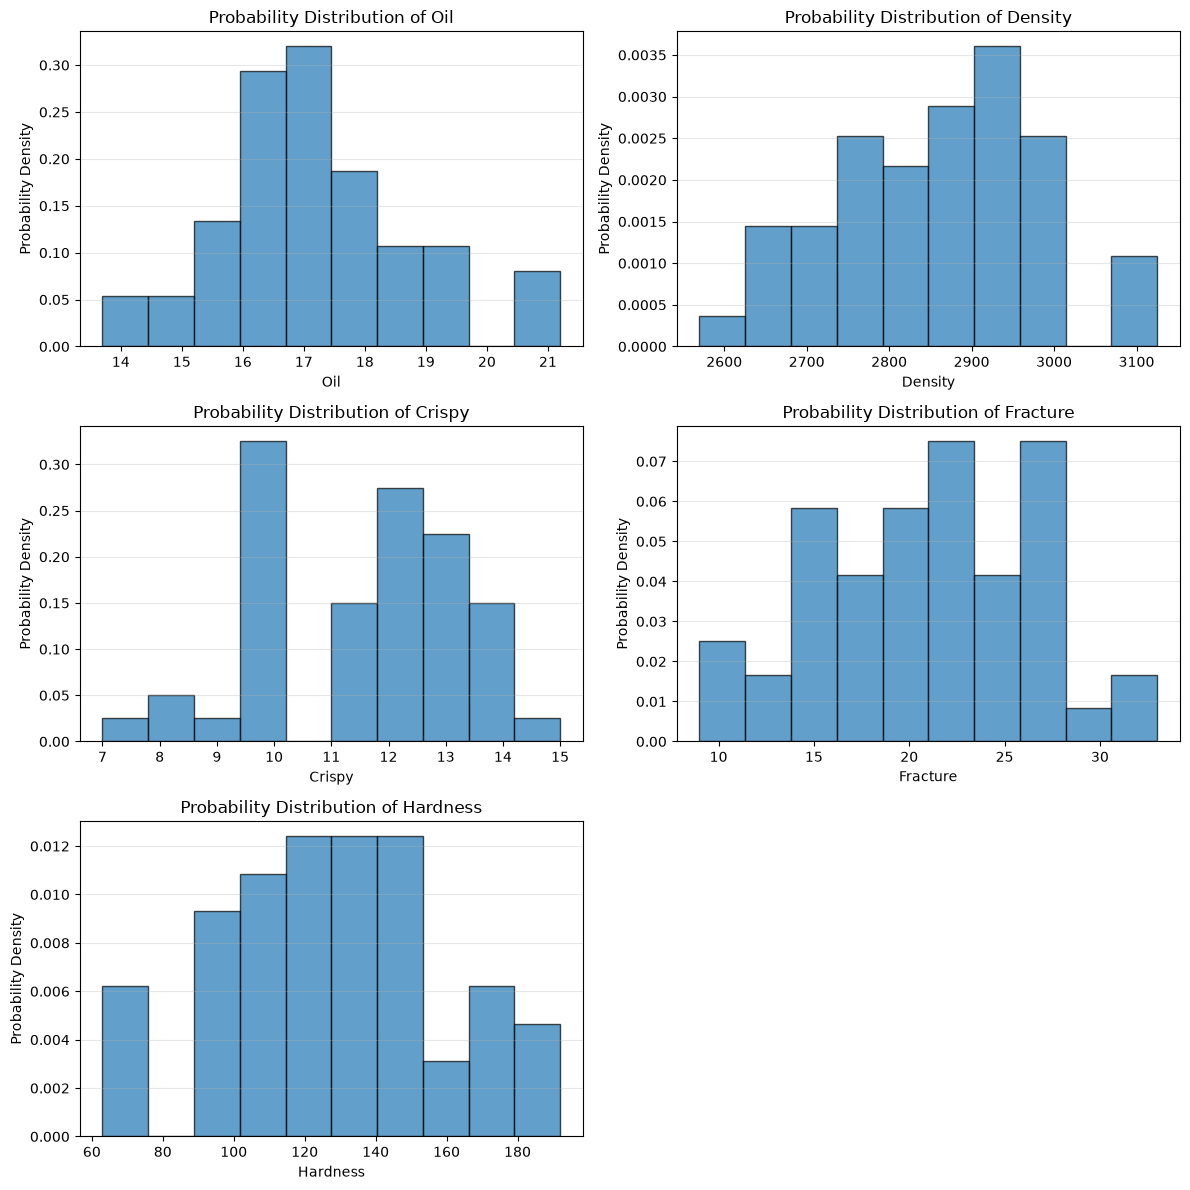

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import math

# Select numerical columns only
numeric_df = df.select_dtypes(include="number")

# Create subplots
n_cols = 2
n_rows = math.ceil(len(numeric_df.columns) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(12, 4 * n_rows))
axes = axes.flatten()

# Plot probability density distributions
for i, column in enumerate(numeric_df.columns):
    axes[i].hist(
        numeric_df[column].dropna(),
        bins=10,
        density=True,
        alpha=0.7,
        edgecolor="black"
    )

    axes[i].set_title(f"Probability Distribution of {column}")
    axes[i].set_xlabel(column)
    axes[i].set_ylabel("Probability Density")
    axes[i].grid(axis="y", alpha=0.3)

# Remove unused subplot axes
for j in range(len(numeric_df.columns), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Pair-wise Comparison of Crispy vs other

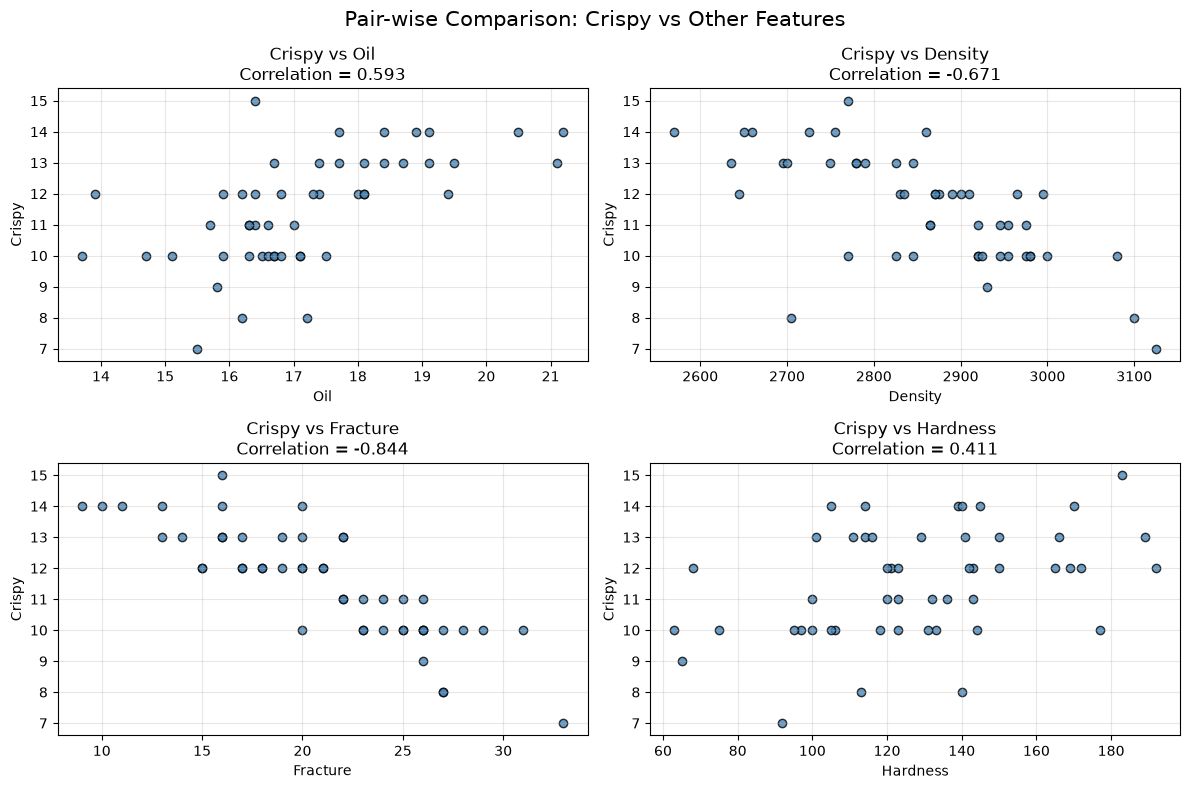

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Exclude ID and select numerical columns
numeric_df = df.drop(columns=["ID"], errors="ignore").select_dtypes(include="number")

# Features to compare with Crispy
features = [col for col in numeric_df.columns if col != "Crispy"]

# Create scatter plots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for i, feature in enumerate(features):
    # Scatter plot
    axes[i].scatter(
        numeric_df[feature],
        numeric_df["Crispy"],
        color="steelblue",
        edgecolor="black",
        alpha=0.8
    )

    # Calculate correlation coefficient
    correlation = numeric_df[feature].corr(numeric_df["Crispy"])

    axes[i].set_title(f"Crispy vs {feature}\nCorrelation = {correlation:.3f}")
    axes[i].set_xlabel(feature)
    axes[i].set_ylabel("Crispy")
    axes[i].grid(True, alpha=0.3)

plt.suptitle("Pair-wise Comparison: Crispy vs Other Features", fontsize=15)
plt.tight_layout()
plt.show()

In [17]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ----- ---------------------------------- 1.0/8.4 MB 6.2 MB/s eta 0:00:02
   ------- -------------------------------- 1.6/8.4 MB 4.2 MB/s eta 0:00:02
   ----------- ---------------------------- 2.4/8.4 MB 4.8 MB/s eta 0:00:02
   ---------------- ----------------------- 3.4/8.4 MB 4.6 MB/s eta 0:00:02
   -------------------- ------------------- 4.2/8.4 MB 4.1 MB/s eta 0:00:02
   ---------------------- ----------------- 4.7/8.4 MB 4.1 MB/s eta 0:00:01
   --------------------------- ------------ 5.8/8.4 MB 4.0 MB/s eta 0:00:01
   ------------------------------ --------- 6.3/8.4 MB 3.9 MB/s eta 0:00:01
   --------------------------------- ------ 7.1/8.4 MB 3.8 MB/s eta 0:00:01
   ------------------------------------- -- 7.9/8.4 MB 3.9 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 3.8 MB/s  0:00:02
   ---------------------------------------- 0.0/37.4 MB ? eta -:--:--
    ------------------------

In [18]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# 1. Define features (X) and target (y)
features = ["Oil", "Density", "Fracture", "Hardness"]
target = "Crispy"

X = df[features]
y = df[target]

# 2. Remove rows with missing values in selected columns
data = pd.concat([X, y], axis=1).dropna()
X = data[features]
y = data[target]

# 3. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 4. Create and train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# 5. Predict Crispy values for the test set
y_pred = model.predict(X_test)

# 6. Evaluate model performance
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MULTIPLE LINEAR REGRESSION RESULTS")
print("-" * 40)
print("Target variable:", target)
print("Features:", features)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nModel Performance:")
print(f"R-squared (R²): {r2:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"Mean Absolute Error (MAE): {mae:.4f}")

# 7. Display regression coefficients
coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_
})

print("\nRegression Coefficients:")
print(coefficients.to_string(index=False))
print(f"\nIntercept: {model.intercept_:.4f}")

# 8. Compare actual and predicted values
results = pd.DataFrame({
    "Actual Crispy": y_test,
    "Predicted Crispy": y_pred
})

results["Prediction Error"] = (
    results["Actual Crispy"] - results["Predicted Crispy"]
)

print("\nActual vs Predicted Crispy:")
print(results.round(3).to_string())


MULTIPLE LINEAR REGRESSION RESULTS
----------------------------------------
Target variable: Crispy
Features: ['Oil', 'Density', 'Fracture', 'Hardness']
Training samples: 40
Testing samples: 10

Model Performance:
R-squared (R²): 0.9352
Mean Squared Error (MSE): 0.2261
Root Mean Squared Error (RMSE): 0.4755
Mean Absolute Error (MAE): 0.4178

Regression Coefficients:
 Feature  Coefficient
     Oil     0.183287
 Density    -0.004324
Fracture    -0.161921
Hardness     0.015489

Intercept: 22.1313

Actual vs Predicted Crispy:
    Actual Crispy  Predicted Crispy  Prediction Error
13             12            11.401             0.599
39             10             9.746             0.254
30             10             9.647             0.353
45             11            10.597             0.403
17             12            12.254            -0.254
48             13            13.531            -0.531
26             10             9.942             0.058
25             12            12.913     

Graph Of Linear Regression

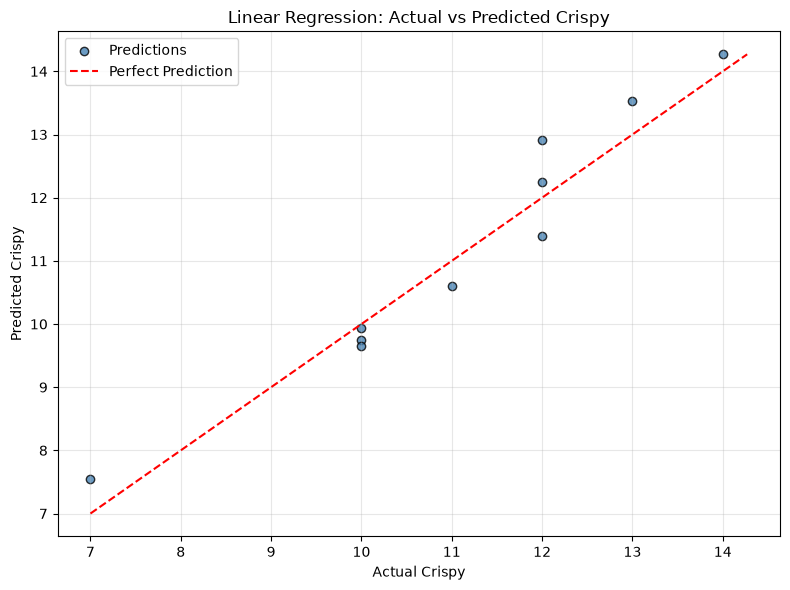

In [19]:
import matplotlib.pyplot as plt

# Plot actual vs predicted values
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, color="steelblue", edgecolor="black",
            alpha=0.8, label="Predictions")

# Ideal prediction line
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())

plt.plot([min_val, max_val], [min_val, max_val],
         "r--", label="Perfect Prediction")

plt.xlabel("Actual Crispy")
plt.ylabel("Predicted Crispy")
plt.title("Linear Regression: Actual vs Predicted Crispy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()